In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\samith allakula\Downloads\archive (5)\Liver_disease_data.csv")

df.head()
df.shape
df.columns
df.info()
df.isnull().sum()
df.duplicated().sum()
df.describe()
df['Diagnosis'].value_counts()      


<class 'pandas.DataFrame'>
RangeIndex: 1700 entries, 0 to 1699
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 1700 non-null   int64  
 1   Gender              1700 non-null   int64  
 2   BMI                 1700 non-null   float64
 3   AlcoholConsumption  1700 non-null   float64
 4   Smoking             1700 non-null   int64  
 5   GeneticRisk         1700 non-null   int64  
 6   PhysicalActivity    1700 non-null   float64
 7   Diabetes            1700 non-null   int64  
 8   Hypertension        1700 non-null   int64  
 9   LiverFunctionTest   1700 non-null   float64
 10  Diagnosis           1700 non-null   int64  
dtypes: float64(4), int64(7)
memory usage: 146.2 KB


Diagnosis
1    936
0    764
Name: count, dtype: int64

In [3]:
df.head()

,Age,Gender,BMI,AlcoholConsumption,Smoking,GeneticRisk,PhysicalActivity,Diabetes,Hypertension,LiverFunctionTest,Diagnosis
0,58,0,35.857584,17.272828,0,1,0.658940,0,0,42.734240,1
1,71,1,30.732470,2.201266,0,1,1.670557,1,0,67.309822,1
2,48,0,19.971407,18.500944,0,0,9.928308,0,0,63.738956,0
3,34,1,16.615417,12.632870,0,0,5.630129,0,0,64.555873,1
4,62,1,16.065830,1.087815,0,1,3.566218,1,0,77.868689,1


In [4]:
#Data Preprocessing

df.isnull().sum()

Age                   0
Gender                0
BMI                   0
AlcoholConsumption    0
Smoking               0
GeneticRisk           0
PhysicalActivity      0
Diabetes              0
Hypertension          0
LiverFunctionTest     0
Diagnosis             0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df['Diagnosis'].value_counts()

Diagnosis
1    936
0    764
Name: count, dtype: int64

In [7]:
df['BMI']

0       35.857584
1       30.732470
2       19.971407
3       16.615417
4       16.065830
          ...    
1695    38.498295
1696    27.600094
1697    38.730017
1698    35.820798
1699    24.060783
Name: BMI, Length: 1700, dtype: float64

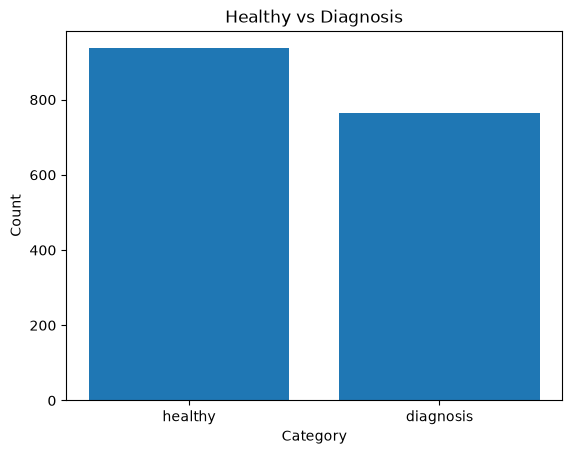

In [8]:
category = ["healthy","diagnosis"]
count = [936,764]
plt.bar(category,count) 
plt.title("Healthy vs Diagnosis")   
plt.xlabel("Category")
plt.ylabel("Count")
plt.show()    

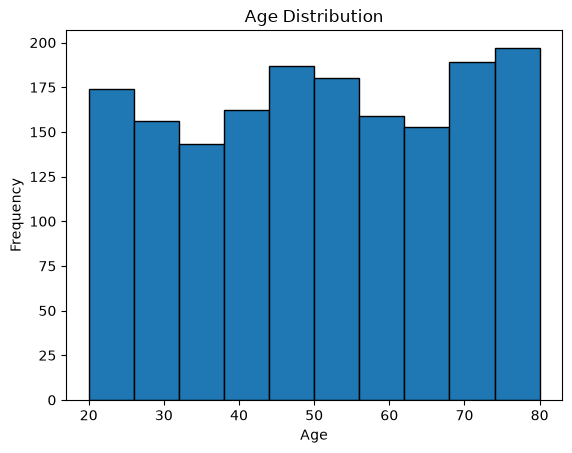

In [9]:
plt.hist(df["Age"],bins=10,edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

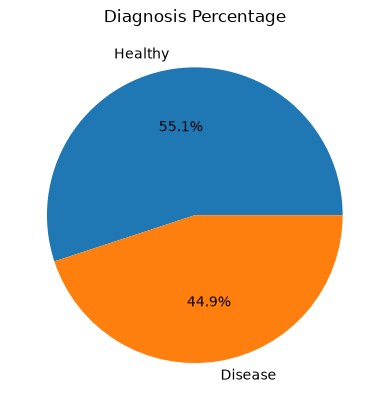

In [ ]:
labels = ["Healthy", "Disease"]
sizes = [936, 764]
plt.pie(sizes,labels=labels, autopct="%1.1f%%")
plt.title("Diagnosis Percentage")
plt.show()

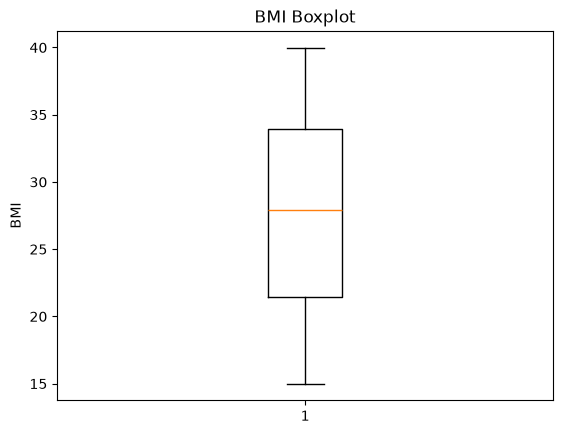

In [ ]:
plt.boxplot(df["BMI"])
plt.title("BMI Boxplot")
plt.ylabel("BMI")
plt.show()

In [12]:
#feature engineering
def heavy_drinker(Alcohol):
    if Alcohol > 15:
        return 1
    else:
        return 0
df["HeavyDrinker"] = df["AlcoholConsumption"].apply(heavy_drinker)
df.head()
    

,Age,Gender,BMI,AlcoholConsumption,Smoking,GeneticRisk,PhysicalActivity,Diabetes,Hypertension,LiverFunctionTest,Diagnosis,HeavyDrinker
0,58,0,35.857584,17.272828,0,1,0.658940,0,0,42.734240,1,1
1,71,1,30.732470,2.201266,0,1,1.670557,1,0,67.309822,1,0
2,48,0,19.971407,18.500944,0,0,9.928308,0,0,63.738956,0,1
3,34,1,16.615417,12.632870,0,0,5.630129,0,0,64.555873,1,0
4,62,1,16.065830,1.087815,0,1,3.566218,1,0,77.868689,1,0


In [ ]:
# interchanging the position of the Heavydrinker column and diagnosis column to divdide the dataset into featres and target variable 
heavy = df.pop("HeavyDrinker")
df.insert(df.columns.get_loc("Diagnosis"), "HeavyDrinker", heavy)
df.head()

,Age,Gender,BMI,AlcoholConsumption,Smoking,GeneticRisk,PhysicalActivity,Diabetes,Hypertension,LiverFunctionTest,HeavyDrinker,Diagnosis
0,58,0,35.857584,17.272828,0,1,0.658940,0,0,42.734240,1,1
1,71,1,30.732470,2.201266,0,1,1.670557,1,0,67.309822,0,1
2,48,0,19.971407,18.500944,0,0,9.928308,0,0,63.738956,1,0
3,34,1,16.615417,12.632870,0,0,5.630129,0,0,64.555873,0,1
4,62,1,16.065830,1.087815,0,1,3.566218,1,0,77.868689,0,1


In [14]:
#feature selection

X=df[['Age','Gender','BMI','AlcoholConsumption','Smoking','GeneticRisk','PhysicalActivity','Diabetes','Hypertension','LiverFunctionTest','HeavyDrinker']]
y=df['Diagnosis']


In [15]:
#Train Test split  
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=1)

#copying original value for randaom forest
X_train = X_train.copy()
X_test= X_test.copy()

In [16]:
# scaled train ,test value for logistic regression 
from sklearn.model_selection import train_test_split
    

X_train_sacled,X_test_scaled,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=1)

from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_sacled=scaler.fit_transform(X_train_sacled)
X_test_scaled=scaler.transform(X_test_scaled)

In [17]:
#Train the model
from sklearn.linear_model import LogisticRegression
my_model = LogisticRegression(max_iter=500)
my_model.fit(X_train_sacled,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",500
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'l

In [18]:
#model evaluation
y_pred = my_model.predict(X_test_scaled)
print("predicted values:",y_pred)

predicted values: [0 0 1 1 0 1 0 0 1 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0 1 0
 0 1 0 1 1 1 0 1 0 1 1 0 0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 1 0 1 0 1 1 1 0 0 1
 0 1 0 1 1 1 1 0 1 0 1 1 0 0 0 0 1 0 1 1 0 0 1 1 0 0 0 1 1 1 1 0 0 1 1 1 0
 1 1 0 1 1 1 0 1 1 1 0 1 0 1 1 0 1 0 0 0 1 0 1 0 1 0 1 0 0 0 0 0 0 1 1 1 0
 0 0 1 1 0 1 0 0 1 1 0 1 1 1 0 0 1 0 0 1 0 0 0 0 0 0 0 0 1 0 1 1 1 0 0 1 1
 1 0 1 1 1 1 1 1 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 0 0 0 0 1 1 1 1 0 1 0 0 1 1
 1 0 1 1 1 1 0 1 0 1 1 0 1 1 1 1 0 0 1 0 1 1 0 1 1 0 1 0 1 0 0 0 1 0 1 0 1
 0 1 1 0 0 1 1 0 1 0 1 1 0 1 1 1 0 0 1 0 1 0 1 0 1 0 0 1 1 0 1 1 1 0 0 0 1
 1 0 0 1 0 1 1 0 0 1 1 1 0 0 0 0 0 1 0 1 1 1 1 1 1 0 0 1 1 1 1 0 0 1 1 1 0
 1 1 0 0 0 0 1]


In [19]:
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
cm = confusion_matrix(y_test,y_pred)
print(cm)
As = accuracy_score(y_test,y_pred)
print(As)
ps = precision_score(y_test,y_pred)
print(ps)
rs = recall_score(y_test,y_pred)
print(rs)
fs = f1_score(y_test,y_pred)
print(fs)
df.head()

[[126  29]
 [ 25 160]]
0.8411764705882353
0.8465608465608465
0.8648648648648649
0.8556149732620321


,Age,Gender,BMI,AlcoholConsumption,Smoking,GeneticRisk,PhysicalActivity,Diabetes,Hypertension,LiverFunctionTest,HeavyDrinker,Diagnosis
0,58,0,35.857584,17.272828,0,1,0.658940,0,0,42.734240,1,1
1,71,1,30.732470,2.201266,0,1,1.670557,1,0,67.309822,0,1
2,48,0,19.971407,18.500944,0,0,9.928308,0,0,63.738956,1,0
3,34,1,16.615417,12.632870,0,0,5.630129,0,0,64.555873,0,1
4,62,1,16.065830,1.087815,0,1,3.566218,1,0,77.868689,0,1


In [20]:
#sample test with new patient data 

sample = [[45,1,28.5,18.0,0,1,3.5,0,0,68.2,1]]
    
sample = scaler.transform(sample)
pred = my_model.predict(sample)
if pred == 1:
    print("liver disease")
else:
    print("healthy")
    print(pred)

# by observation has liver function test high they are suffering with liver disease 

liver disease


c:\Users\samith allakula\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [21]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=400,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    
)

rf_model.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",400
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [22]:
#prediction after hyperparameter tuning
rf_pred = rf_model.predict(X_test)
print(rf_pred)

[0 0 1 1 0 1 0 1 1 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 0 1 1 0 0 0
 0 0 1 1 1 0 0 0 0 1 1 1 0 0 0 0 0 0 1 0 0 1 0 0 1 0 0 1 0 1 0 1 0 1 0 0 1
 0 1 0 1 1 1 0 0 1 0 1 1 1 0 0 0 1 0 0 1 0 0 1 1 0 0 0 1 1 0 0 1 0 1 1 1 0
 0 1 0 1 1 1 0 1 1 1 1 1 1 0 1 1 1 0 0 0 1 1 1 0 1 1 1 1 1 0 0 0 0 1 1 1 0
 0 0 0 1 0 1 1 0 1 1 0 1 1 1 0 1 1 0 0 1 1 0 0 1 1 0 1 0 1 0 1 1 1 0 0 0 1
 0 0 1 1 1 1 0 1 1 0 0 0 0 1 1 1 0 1 0 1 0 0 1 0 0 0 0 1 1 1 1 0 1 0 0 1 1
 1 1 1 1 0 1 0 1 0 1 1 1 0 1 1 1 0 0 1 0 1 1 0 1 1 1 1 0 1 0 0 0 0 0 1 1 1
 0 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 0 0 1 0 1 1 1 0 1 0 0 1 1 0 0 1 1 0 0 0 1
 1 0 0 0 0 1 0 0 0 1 1 1 1 0 0 0 0 1 0 1 1 1 1 1 1 0 0 1 1 0 1 0 1 1 1 1 0
 1 1 0 0 0 0 1]


In [23]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
as1 = accuracy_score(y_test,rf_pred)
print(as1)
ps1 = precision_score(y_test,rf_pred)
print(ps1)
rs1 = recall_score(y_test,rf_pred)
print(rs1)
fs1 = f1_score(y_test,rf_pred)
print(fs1)

0.9
0.8994708994708994
0.918918918918919
0.9090909090909091


In [24]:
sample = pd.DataFrame({
    "Age":[45],
    "Gender":[1],
    "BMI":[28.5],
    "AlcoholConsumption":[18],
    "Smoking":[0],
    "GeneticRisk":[1],
    "PhysicalActivity":[3.5],
    "Diabetes":[0],
    "Hypertension":[0],
    "LiverFunctionTest":[68.2],
    "HeavyDrinker":[1]
})

prediction = rf_model.predict(sample)
print(prediction)

[1]


In [25]:
print(df.shape)
print(df["Diagnosis"].value_counts())

(1700, 12)
Diagnosis
1    936
0    764
Name: count, dtype: int64


In [26]:
print(X_train.shape)
print(y_train.shape)

(1360, 11)
(1360,)


In [27]:
#hyperparameter tuning using GridsearchCV
from sklearn.model_selection import GridSearchCV
rf_model = RandomForestClassifier(random_state=42)
param_grid = {
    "n_estimators": [100, 200,300],
    "max_depth": [5, 10,15 ],
    "min_samples_split": [2, 5,10],
    "min_samples_leaf": [1, 2, 4 ]
}
    
grid = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)


print(grid.param_grid)   #prints the parameter of girdsearchCV
grid.fit(X_train, y_train) # trains the random forest trys every combination of hyperterparameter and find best parameters 
print("Best parameters:", grid.best_params_) 



{'n_estimators': [100, 200, 300], 'max_depth': [5, 10, 15], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4]}
Best parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 300}


In [28]:
grid.best_estimator_

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [29]:
best_rf = grid.best_estimator_
print(best_rf)


RandomForestClassifier(max_depth=10, min_samples_leaf=4, n_estimators=300,
                       random_state=42)


In [30]:
y_pred = best_rf.predict(X_test)
print(y_pred)

[0 0 1 1 0 1 0 1 1 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 0 1 1 0 0 0
 0 0 1 1 1 0 0 0 0 1 1 1 0 1 0 0 0 0 1 0 0 1 0 0 1 0 0 1 0 1 0 1 0 1 0 0 1
 0 1 1 1 1 1 0 0 1 0 1 1 1 0 0 0 1 0 0 1 0 0 1 1 0 0 0 1 1 0 0 1 0 1 1 1 0
 0 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 0 0 0 1 1 1 0 1 1 1 1 1 0 0 0 0 1 1 1 0
 0 0 1 1 0 1 1 0 1 1 0 1 1 1 0 1 1 0 0 1 1 0 0 1 1 0 1 0 1 0 1 1 1 0 0 0 1
 0 0 1 1 1 1 0 1 1 0 0 0 0 0 1 1 0 1 0 1 0 0 1 0 0 0 0 1 1 1 1 0 1 0 0 1 1
 1 1 1 1 0 1 0 1 0 1 1 1 0 1 1 1 0 0 1 0 1 1 0 1 1 1 1 0 1 0 0 0 0 0 1 1 1
 0 1 1 0 0 1 1 1 1 0 1 1 1 1 1 0 0 0 1 0 1 1 1 0 1 0 0 1 1 0 0 1 1 0 0 0 1
 1 0 0 0 0 1 1 0 0 1 1 1 1 0 0 0 0 1 0 1 1 1 1 1 1 0 0 1 1 0 1 0 1 1 1 1 0
 1 1 0 0 0 0 1]


In [31]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
recall = recall_score(y_test,y_pred)
print("Recall:", recall)
precision = precision_score(y_test,y_pred)
print("Precision:", precision)
f1 = f1_score(y_test,y_pred)
print("F1 Score:", f1)


Accuracy: 0.8911764705882353
Recall: 0.918918918918919
Precision: 0.8854166666666666
F1 Score: 0.9018567639257294


In [32]:
#Feature importance 
importance = best_rf.feature_importances_

feature_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": importance 

})

feature_importance = feature_importance.sort_values(by="importance",ascending=False)
print(feature_importance)



               feature  importance
9    LiverFunctionTest    0.267417
3   AlcoholConsumption    0.240468
0                  Age    0.096704
2                  BMI    0.087437
6     PhysicalActivity    0.082555
4              Smoking    0.050104
5          GeneticRisk    0.048588
1               Gender    0.047738
10        HeavyDrinker    0.039034
8         Hypertension    0.028094
7             Diabetes    0.011861


In [33]:
# prediction for new patient 
import pandas as pd
new_patient = pd.DataFrame({
    "Age": [45],
    "Gender": [1],
    "BMI": [28],
    "AlcoholConsumption": [18],
    "Smoking": [1],
    "GeneticRisk": [1],
    "PhysicalActivity": [3],
    "Diabetes": [0],
    "Hypertension": [1],
    "LiverFunctionTest": [65],
    "HeavyDrinker": [1]
})

In [34]:
prediction = best_rf.predict(new_patient)

print("Prediction:", prediction)

Prediction: [1]


In [35]:
import joblib
joblib.dump(best_rf,"liver_disease_model.pkl")
print("model sucessfully saved")

model sucessfully saved


In [36]:
import joblib
load_model = joblib.load("liver_disease_model.pkl")
print(load_model)

RandomForestClassifier(max_depth=10, min_samples_leaf=4, n_estimators=300,
                       random_state=42)
